# Ошибка округления при вычислении интегралов по рекурсии

**Задача.** Вычислить
$$I_k=\int_0^1 x^k e^x\,dx,\qquad k=1,\ldots,20,$$
объяснить разброс результатов прямой рекурсии при больших $k$ и показать устойчивый способ вычисления. Результаты всех ячеек и рисунки сохранены в этом ноутбуке: его можно открыть без повторного запуска.

Будем сравнивать обычные числа `float64` (около 16 значащих десятичных цифр), расчёт с 80 десятичными знаками и обратную рекурсию. Графики изображают **ошибку метода вычисления**, а не физическую или статистическую случайность.

In [1]:
# При необходимости установите зависимости заранее: %pip install numpy matplotlib mpmath scipy
import math
import numpy as np
import mpmath as mp
import matplotlib.pyplot as plt
from scipy.integrate import quad
from IPython.display import display, Markdown

mp.mp.dps=80
K=20
ks=np.arange(K+1)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.grid':True,'grid.alpha':.25})

## 1. Вывод прямой рекурсии

Интегрируем по частям: $u=x^k$, $dv=e^x\,dx$. Тогда $du=kx^{k-1}\,dx$, $v=e^x$ и при $k\ge1$
$$I_k=\left[x^ke^x\right]_0^1-k\int_0^1x^{k-1}e^x\,dx
=e-kI_{k-1}.$$
Начальное значение вычисляется точно:
$$I_0=\int_0^1e^x\,dx=e-1.$$
Итак, для последовательного вычисления достаточно двух формул: **$I_0=e-1$, $I_k=e-kI_{k-1}$**. Все интегралы положительны; поскольку $1\le e^x\le e$ на $[0,1]$, имеем полезную проверку
$$\frac1{k+1}\le I_k\le\frac e{k+1}.$$
Если численный результат отрицателен или выходит за эти границы, вычисление уже недостоверно.

In [2]:
forward=np.empty(K+1,dtype=float)
forward[0]=math.e-1.0  # База I_0; число e в float64 уже округлено.
for k in range(1,K+1):
    forward[k]=math.e-k*forward[k-1]  # Формула интегрирования по частям.
print('Первые пять значений прямой рекурсии:',[f'{v:.9f}' for v in forward[:5]])

Первые пять значений прямой рекурсии: ['1.718281828', '1.000000000', '0.718281828', '0.563436343', '0.464536456']


## 2. Независимые опорные значения

Для сравнения вычислим тот же интеграл с 80 десятичными знаками функцией `mp.quad`. Это **не та же прямая рекурсия**, поэтому сравнение выявляет её ошибку. Дополнительно `scipy.integrate.quad` независимо вычисляет интегралы в обычной двойной точности. Точность `mp.quad` проверяется положительностью и аналитическими границами выше.

In [3]:
reference_mp=[mp.quad(lambda x, k=k: x**k*mp.exp(x), [0,1]) for k in range(K+1)]
reference=np.array([float(value) for value in reference_mp])
direct_quad=np.array([quad(lambda x, k=k: x**k*np.exp(x),0,1,epsabs=1e-13)[0] for k in range(K+1)])
assert all(mp.mpf(1)/(k+1)<=v<=mp.e/(k+1) for k,v in enumerate(reference_mp))
assert np.allclose(direct_quad,reference,rtol=1e-12,atol=1e-13)

lines=['| k | Прямая рекурсия float64 | Опорное значение | Абсолютная ошибка |',
       '|---:|---:|---:|---:|']
for k in range(K+1):
    lines.append(f'| {k} | {forward[k]:.10g} | {reference[k]:.10g} | {abs(forward[k]-reference[k]):.3g} |')
display(Markdown('\n'.join(lines)))

| k | Прямая рекурсия float64 | Опорное значение | Абсолютная ошибка |
|---:|---:|---:|---:|
| 0 | 1.718281828 | 1.718281828 | 2.22e-16 |
| 1 | 1 | 1 | 0 |
| 2 | 0.7182818285 | 0.7182818285 | 1.11e-16 |
| 3 | 0.5634363431 | 0.5634363431 | 3.33e-16 |
| 4 | 0.4645364561 | 0.4645364561 | 1.28e-15 |
| 5 | 0.3955995478 | 0.3955995478 | 6.38e-15 |
| 6 | 0.3446845416 | 0.3446845416 | 3.83e-14 |
| 7 | 0.3054900369 | 0.3054900369 | 2.68e-13 |
| 8 | 0.274361533 | 0.274361533 | 2.14e-12 |
| 9 | 0.2490280313 | 0.2490280313 | 1.93e-11 |
| 10 | 0.2280015153 | 0.2280015155 | 1.93e-10 |
| 11 | 0.2102651602 | 0.2102651581 | 2.12e-09 |
| 12 | 0.1950999057 | 0.1950999312 | 2.55e-08 |
| 13 | 0.1819830545 | 0.1819827234 | 3.31e-07 |
| 14 | 0.170519065 | 0.1705237013 | 4.64e-06 |
| 15 | 0.1604958542 | 0.1604263089 | 6.95e-05 |
| 16 | 0.1503481618 | 0.1514608855 | 0.00111 |
| 17 | 0.1623630772 | 0.1434467743 | 0.0189 |
| 18 | -0.2042535616 | 0.136239891 | 0.34 |
| 19 | 6.599099498 | 0.1297238999 | 6.47 |
| 20 | -129.2637081 | 0.1238038308 | 129 |

## 3. Почему появляется и растёт разброс

Пусть вместо точного $I_k$ получено $\widetilde I_k=I_k+\delta_k$. Если считать, что в очередном шаге **нет новой** ошибки округления, то
$$\delta_k=(e-k\widetilde I_{k-1})-(e-kI_{k-1})=-k\delta_{k-1},$$
а после $k$ шагов $\delta_k=(-1)^k k!\delta_0$. Так, $20!\approx2{,}43\cdot10^{18}$: ошибка порядка $10^{-16}$ в начале может превратиться в ошибку порядка сотен. В реальном `float64` округление добавляется на **каждом** шаге, поэтому это уравнение объясняет главную причину роста, но не предсказывает каждую последнюю цифру.

Здесь вычитаются два близких числа: $e$ и $kI_{k-1}$. Их разность, то есть $I_k$, сравнительно мала. Это **потеря значащих цифр при вычитании**. На разных компьютерах или при немного разном порядке вычислений начальные и промежуточные ошибки отличаются; рекурсия усиливает их по факториальному закону. Поэтому у студентов разброс может начаться на разных шагах и иметь разные знаки. Это не случайный разброс исходных интегралов.

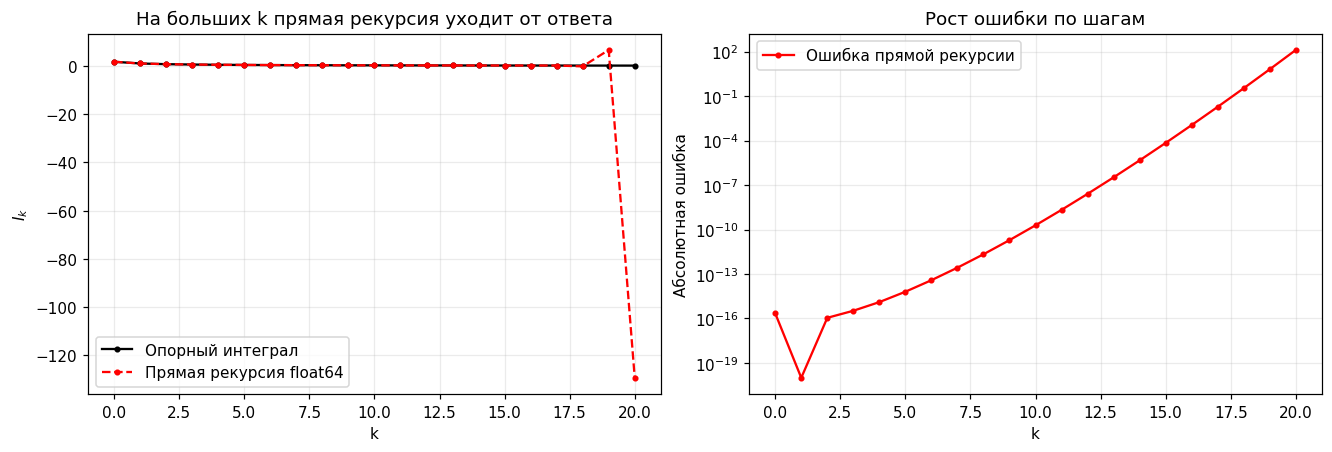

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].plot(ks,reference,'ko-',ms=3,label='Опорный интеграл')
axes[0].plot(ks,forward,'r.--',label='Прямая рекурсия float64')
axes[0].set(xlabel='k',ylabel=r'$I_k$',title='На больших k прямая рекурсия уходит от ответа')
axes[0].legend()
axes[1].semilogy(ks,np.maximum(np.abs(forward-reference),1e-20),'ro-',ms=3,label='Ошибка прямой рекурсии')
axes[1].set(xlabel='k',ylabel='Абсолютная ошибка',title='Рост ошибки по шагам')
axes[1].legend()
plt.show()

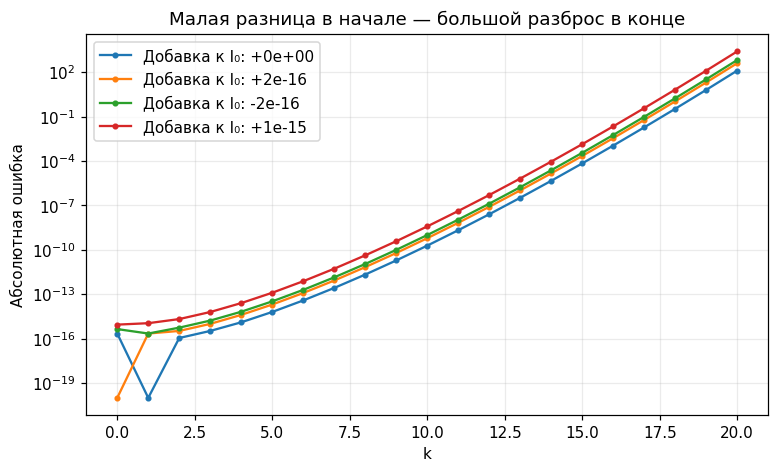

In [5]:
# Повторяем прямую рекурсию, изменяя только начальное число на очень малую величину.
seeds=[0.0,2e-16,-2e-16,1e-15]
fig,ax=plt.subplots(figsize=(8,4.5))
for perturbation in seeds:
    values=np.empty(K+1)
    values[0]=(math.e-1)+perturbation
    for k in range(1,K+1):
        values[k]=math.e-k*values[k-1]
    ax.semilogy(ks,np.maximum(np.abs(values-reference),1e-20),marker='.',label=f'Добавка к I₀: {perturbation:+.0e}')
ax.set(xlabel='k',ylabel='Абсолютная ошибка',title='Малая разница в начале — большой разброс в конце')
ax.legend();plt.show()

## 4. Исправление: обратная рекурсия

Перепишем ту же точную формулу так, чтобы считать **от большого индекса к малому**:
$$I_{k-1}=\frac{e-I_k}{k}.$$
Теперь ошибка передаётся по правилу $\delta_{k-1}=-\delta_k/k$, то есть **делится на $k$**, а не умножается. Начнём с $N=60$ и грубой оценки $I_{60}=0$. Она неверна, но истинное значение удовлетворяет $0<I_{60}\le e/61$. При движении назад до $k=20$ влияние этой начальной ошибки уменьшается не менее чем в $60!/20!$ раз:
$$|\delta_{20}|\le\frac e{61}\frac{20!}{60!}.$$
На практике округление внутри обратных шагов тоже существует, но не усиливается факториально. Этот способ даёт устойчивые ответы для нужных $k=1,\ldots,20$.

In [6]:
N=60
backward=np.empty(N+1,dtype=float)
backward[N]=0.0  # Грубое начальное приближение на далёком шаге.
for k in range(N,0,-1):
    backward[k-1]=(math.e-backward[k])/k  # Обратная устойчивая формула.

backward_error=np.abs(backward[:K+1]-reference)
forward_error=np.abs(forward-reference)
print(f'I_20: прямой ход = {forward[20]:.12g}')
print(f'I_20: обратный ход = {backward[20]:.12g}')
print(f'I_20: опорный интеграл = {reference[20]:.12g}')
print(f'Максимальная ошибка обратного хода на 1..20: {backward_error[1:].max():.3g}')
print(f'Теоретическая граница ошибки стартового I_60 в I_20: {math.e/61*math.factorial(20)/math.factorial(60):.3g}')
assert np.allclose(backward[:K+1],reference,rtol=1e-13,atol=1e-14)
assert backward_error[20] < forward_error[20]

I_20: прямой ход = -129.263708133
I_20: обратный ход = 0.123803830763
I_20: опорный интеграл = 0.123803830763
Максимальная ошибка обратного хода на 1..20: 5.55e-17
Теоретическая граница ошибки стартового I_60 в I_20: 1.3e-65


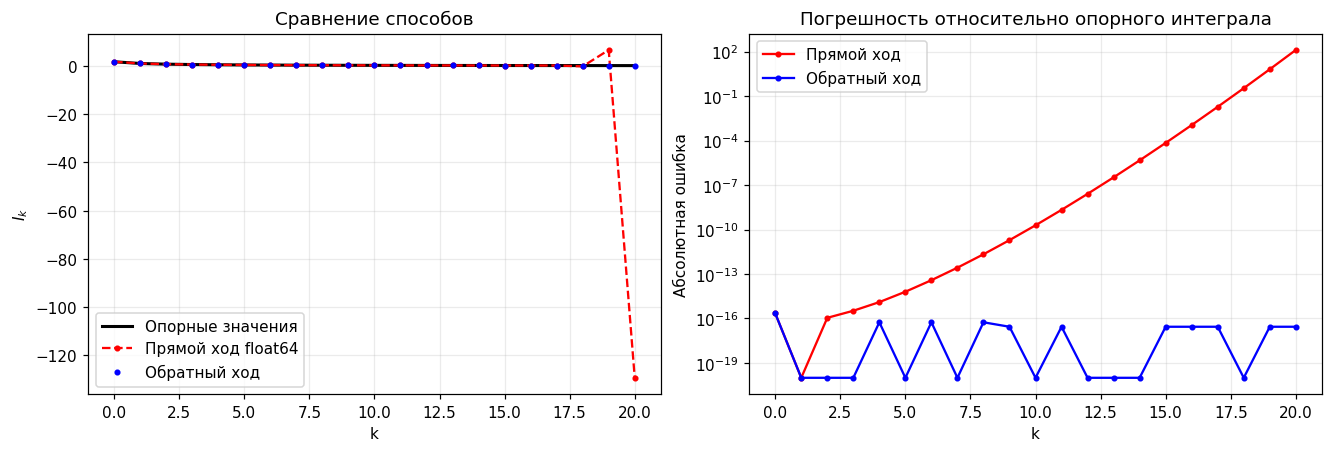

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
axes[0].plot(ks,reference,'k-',lw=2,label='Опорные значения')
axes[0].plot(ks,forward,'r.--',label='Прямой ход float64')
axes[0].plot(ks,backward[:K+1],'bo',ms=3,label='Обратный ход')
axes[0].set(xlabel='k',ylabel=r'$I_k$',title='Сравнение способов');axes[0].legend()
axes[1].semilogy(ks,np.maximum(forward_error,1e-20),'r.-',label='Прямой ход')
axes[1].semilogy(ks,np.maximum(backward_error,1e-20),'b.-',label='Обратный ход')
axes[1].set(xlabel='k',ylabel='Абсолютная ошибка',title='Погрешность относительно опорного интеграла')
axes[1].legend();plt.show()

## Вывод для защиты

Прямая рекурсия $I_k=e-kI_{k-1}$ **математически верна**, но для больших $k$ **численно неустойчива**: накопленная погрешность умножается примерно на $k!$. Поэтому разные минимальные ошибки округления дают заметно разные ответы. Исправление — считать рекурсию назад от достаточно большого $N$ либо вычислять каждый интеграл независимым устойчивым численным методом. Совпадение обратного хода с высокоточным интегрированием и аналитическими границами проверено кодом выше.